In [82]:
from google.colab import drive
import pandas as pd

# Monta o Google Drive
drive.mount('/content/drive')

# Define o caminho do arquivo
caminho_arquivo = '/content/drive/MyDrive/Estudos/Churn/clientes_base.csv'

# Carrega o DataFrame
try:
    df = pd.read_csv(caminho_arquivo)
    print("Arquivo carregado com sucesso!")
except FileNotFoundError:
    print(f"Erro: Arquivo não encontrado no caminho: {caminho_arquivo}")
    print("Por favor, verifique se o caminho da pasta no seu Drive está correto.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Arquivo carregado com sucesso!


In [83]:
# Exibe as primeiras linhas do DataFrame
display(df.head())

# Exibe as informações das colunas e seus tipos de dados
print("\n--- Informações das Colunas ---")
df.info()

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0



--- Informações das Colunas ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   cliente_id              5025 non-null   int64  
 1   idade                   5025 non-null   int64  
 2   plano                   5025 non-null   object 
 3   ciclo                   5025 non-null   object 
 4   valor_mensal            5025 non-null   float64
 5   regiao                  5025 non-null   object 
 6   canal_aquisicao         5025 non-null   object 
 7   nps                     5025 non-null   int64  
 8   data_assinatura         5025 non-null   object 
 9   data_cancelamento       1516 non-null   object 
 10  data_ultimo_acesso      4975 non-null   object 
 11  data_extracao           5025 non-null   object 
 12  dias_ativos_ult_mes     5025 non-null   int64  
 13  horas_assistidas_total  5025 non-null   float64
 14  motivo_


--- Contagem para a coluna: plano ---
plano
Basico     708
BASICO     677
básico     677
Padrao     665
Padrão     654
padrão     646
premium    513
Premium    485
Name: count, dtype: int64

--- Contagem para a coluna: ciclo ---
ciclo
Mensal    3794
Anual     1231
Name: count, dtype: int64

--- Contagem para a coluna: regiao ---
regiao
Sudeste         2057
Nordeste         964
Sul              938
Centro-Oeste     488
Norte            408
?                170
Name: count, dtype: int64

--- Contagem para a coluna: canal_aquisicao ---
canal_aquisicao
Organico     781
orgânico     729
Indicacao    556
IG           529
indicação    526
Instagram    519
instagram    499
Google       452
google       434
Name: count, dtype: int64


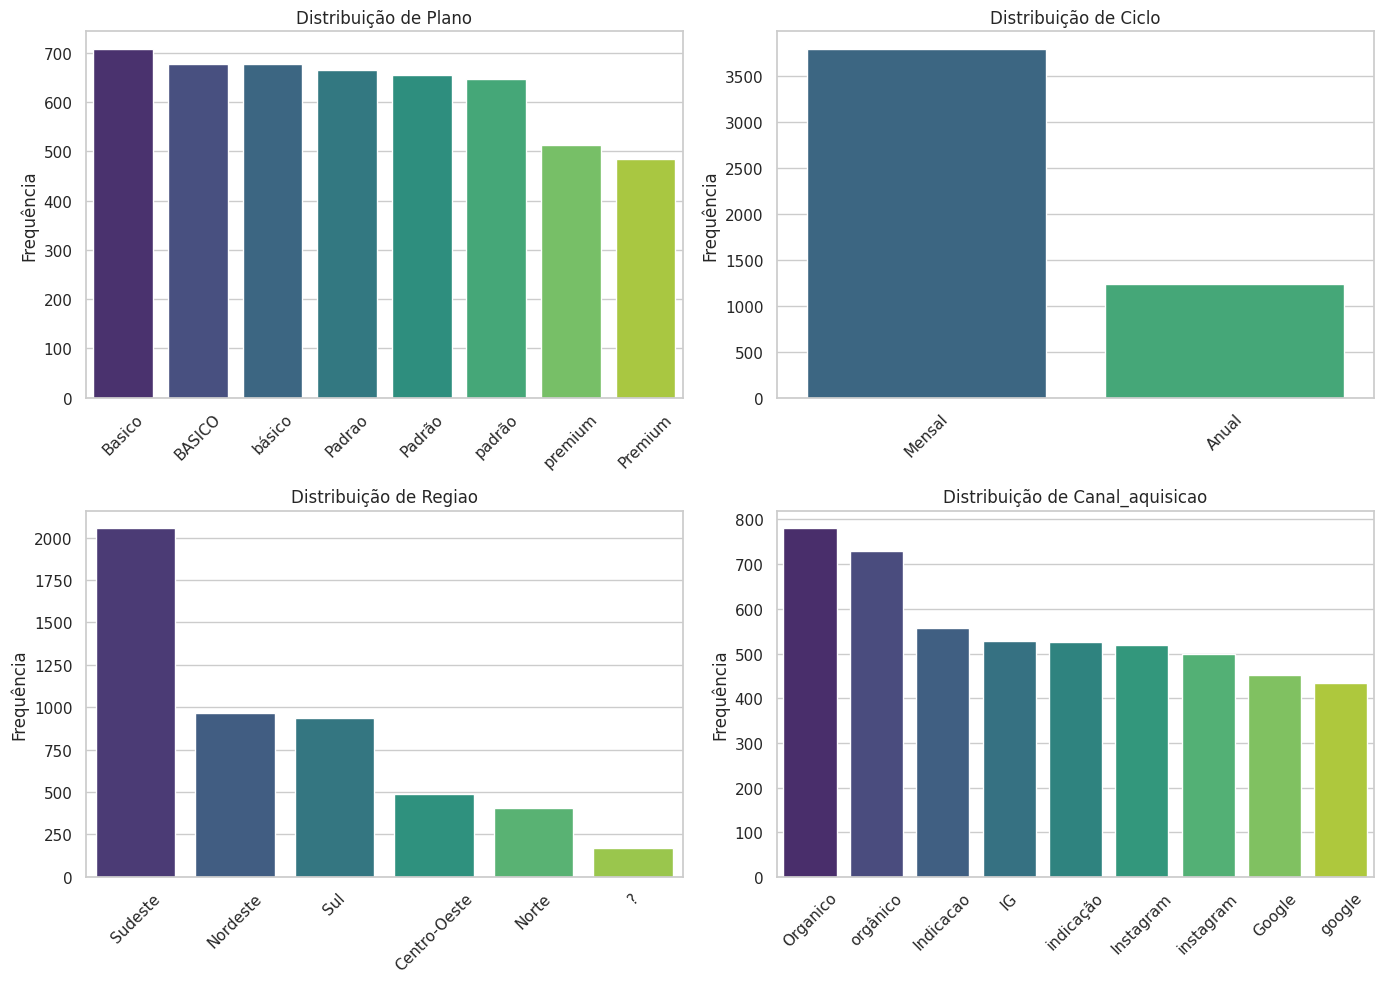

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns

colunas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

# Configura o estilo dos gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(colunas):
    # Contagem de valores únicos
    contagem = df[col].value_counts()
    print(f"\n--- Contagem para a coluna: {col} ---")
    print(contagem)

    # Gráfico de barras
    sns.barplot(x=contagem.index, y=contagem.values, ax=axes[i], palette='viridis', hue=contagem.index, legend=False)
    axes[i].set_title(f'Distribuição de {col.capitalize()}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequência')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [85]:
# 1. Contando os valores nulos em cada coluna
valores_nulos = df.isnull().sum()
display(valores_nulos)

,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [86]:
# 2. Filtrando e exibindo exemplos onde regiao == '?'
df_regiao_interrogacao = df[df['regiao'] == '?']
display(df_regiao_interrogacao.head(5))

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,Basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,básico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrão,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrão,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0


In [87]:
# Mapeamento para padronização da coluna 'plano'
mapa_plano = {
    'Basico': 'Basico',
    'BASICO': 'Basico',
    'básico': 'Basico',
    'Padrao': 'Padrão',
    'Padrão': 'Padrão',
    'padrão': 'Padrão',
    'premium': 'Premium',
    'Premium': 'Premium'
}

# Mapeamento para padronização da coluna 'canal_aquisicao'
mapa_canal = {
    'Organico': 'Organico',
    'orgânico': 'Organico',
    'Indicacao': 'Indicacao',
    'indicação': 'Indicacao',
    'IG': 'Instagram',
    'instagram': 'Instagram',
    'Instagram': 'Instagram',
    'Google': 'Google',
    'google': 'Google'
}

# Aplicando as substituições
df['plano'] = df['plano'].map(mapa_plano).fillna(df['plano'])
df['canal_aquisicao'] = df['canal_aquisicao'].map(mapa_canal).fillna(df['canal_aquisicao'])

# Exibindo os resultados após a padronização
print("--- Distribuição de Plano (Padronizado) ---")
print(df['plano'].value_counts())

print("\n--- Distribuição de Canal de Aquisição (Padronizado) ---")
print(df['canal_aquisicao'].value_counts())

--- Distribuição de Plano (Padronizado) ---
plano
Basico     2062
Padrão     1965
Premium     998
Name: count, dtype: int64

--- Distribuição de Canal de Aquisição (Padronizado) ---
canal_aquisicao
Instagram    1547
Organico     1510
Indicacao    1082
Google        886
Name: count, dtype: int64


In [88]:
import numpy as np

# substituir '?' por nulo em todo o DataFrame

df = df.replace ('?', np.nan)

print("Quantidade de valores nulos por coluna após a substituição:")
display(df.isnull().sum())

Quantidade de valores nulos por coluna após a substituição:


,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [89]:
df

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,Basico,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,Organico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,Organico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,Basico,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,Indicacao,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5020,1789,21,Padrão,Mensal,34.9,Nordeste,Indicacao,8,2022-11-22,NaN,2024-01-12,2024-01-31,13,424.9,NaN,0
5021,1968,42,Padrão,Mensal,34.9,Sudeste,Indicacao,6,2021-07-26,NaN,2024-01-07,2024-01-31,15,900.0,NaN,0
5022,2667,66,Padrão,Mensal,34.9,Sudeste,Organico,9,2023-05-26,NaN,2024-01-25,2024-01-31,14,232.2,NaN,0
5023,4321,39,Basico,Mensal,19.9,Sudeste,Indicacao,7,2022-12-16,NaN,2024-01-04,2024-01-31,16,448.2,NaN,0


In [90]:
# Lista das colunas que contêm datas
colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

# Converte cada uma das colunas para datetime
for col in colunas_data:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Exibe as informações para confirmar a alteração dos tipos
print("--- Tipos de dados atualizados ---")
df[colunas_data].info()

--- Tipos de dados atualizados ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   data_assinatura     5025 non-null   datetime64[ns]
 1   data_cancelamento   1516 non-null   datetime64[ns]
 2   data_ultimo_acesso  4975 non-null   datetime64[ns]
 3   data_extracao       5025 non-null   datetime64[ns]
dtypes: datetime64[ns](4)
memory usage: 157.2 KB


In [91]:
# Calculando a diferença em dias entre as colunas de datas

# 1. Dias até o cancelamento (apenas para quem cancelou)
df['dias_ate_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days

# 2. Dias desde o último acesso (inatividade até a data de extração)
df['dias_desde_ultimo_acesso'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# 3. Tempo de vida total do cliente ativo (desde a assinatura até o último acesso)
df['tempo_vida_cliente'] = (df['data_ultimo_acesso'] - df['data_assinatura']).dt.days

# Exibindo uma amostra das novas colunas criadas
colunas_novas = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao', 'dias_ate_cancelamento', 'dias_desde_ultimo_acesso', 'tempo_vida_cliente']
display(df[colunas_novas].head(5))

,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente
0,2023-04-11,NaT,2024-01-29,2024-01-31,NaN,2.0,293.0
1,2022-06-02,NaT,2024-01-30,2024-01-31,NaN,1.0,607.0
2,2021-03-20,2022-11-17,2022-10-31,2024-01-31,607.0,457.0,590.0
3,2023-04-02,NaT,2024-01-13,2024-01-31,NaN,18.0,286.0
4,2023-04-21,NaT,2024-01-16,2024-01-31,NaN,15.0,270.0


In [92]:
# Lista das novas colunas calculadas
colunas_calculadas = ['dias_ate_cancelamento', 'dias_desde_ultimo_acesso', 'tempo_vida_cliente','dias_ate_cancelamento']

# Verificação de valores negativos para cada coluna
for col in colunas_calculadas:
    negativos = df[df[col] < 0]
    print(f"Coluna '{col}':")
    print(f"  - Quantidade de valores negativos: {len(negativos)}")
    if len(negativos) > 0:
        print(f"  - Exemplos com valores negativos na coluna {col}:")
        display(negativos[['cliente_id', 'data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao', col]].head(5))
    print("-" * 50)

Coluna 'dias_ate_cancelamento':
  - Quantidade de valores negativos: 0
--------------------------------------------------
Coluna 'dias_desde_ultimo_acesso':
  - Quantidade de valores negativos: 0
--------------------------------------------------
Coluna 'tempo_vida_cliente':
  - Quantidade de valores negativos: 1
  - Exemplos com valores negativos na coluna tempo_vida_cliente:


,cliente_id,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,tempo_vida_cliente
11,3426,2023-08-18,2023-11-16,2023-07-02,2024-01-31,-47.0


--------------------------------------------------
Coluna 'dias_ate_cancelamento':
  - Quantidade de valores negativos: 0
--------------------------------------------------


In [93]:
# 1. Identifica e cria uma lista de colunas numéricas (inteiros e floats)
colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("Colunas numéricas encontradas:", colunas_numericas)

# 2. Retorna a contagem de valores preenchidos em cada uma dessas colunas
print("\n--- Quantidade de números (valores não nulos) por coluna ---")
display(df[colunas_numericas].count())

# 3. Retorna as estatísticas descritivas (média, desvio padrão, min, max, etc.)
print("\n--- Estatísticas Descritivas das Colunas Numéricas ---")
display(df[colunas_numericas].describe())

Colunas numéricas encontradas: ['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'dias_ate_cancelamento', 'dias_desde_ultimo_acesso', 'tempo_vida_cliente']

--- Quantidade de números (valores não nulos) por coluna ---


,0
cliente_id,5025
idade,5025
valor_mensal,5025
nps,5025
dias_ativos_ult_mes,5025
horas_assistidas_total,5025
churn,5025
dias_ate_cancelamento,1516
dias_desde_ultimo_acesso,4975
tempo_vida_cliente,4975



--- Estatísticas Descritivas das Colunas Numéricas ---


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,dias_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente
count,5025.000000,5025.000000,5025.00000,5025.000000,5025.000000,5025.000000,5025.000000,1516.000000,4975.000000,4975.000000
mean,3497.592438,36.329154,416.08394,6.409751,10.653731,281.856796,0.301692,220.407652,40.451859,372.186533
std,1443.146051,11.678632,1127.94888,2.435118,6.000091,254.707091,0.459038,145.004268,55.107192,277.107592
min,1000.000000,-2.000000,19.90000,0.000000,0.000000,0.000000,0.000000,11.000000,0.000000,-47.000000
25%,2248.000000,29.000000,19.90000,5.000000,5.000000,65.400000,0.000000,118.000000,10.000000,163.000000
50%,3496.000000,36.000000,34.90000,7.000000,12.000000,208.600000,0.000000,182.500000,20.000000,307.000000
75%,4747.000000,44.000000,55.90000,8.000000,15.000000,427.700000,1.000000,288.500000,44.000000,512.000000
max,5999.000000,300.000000,5590.00000,10.000000,28.000000,900.000000,1.000000,1067.000000,469.000000,1809.000000


In [94]:
df.isnull().sum()

,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [95]:
# Criando o filtro: tempo_vida_cliente deve ser >= 0 ou nulo (isna)
filtro_consistente = (df['tempo_vida_cliente'] >= 0) | (df['tempo_vida_cliente'].isna())

# Exibindo o tamanho antes de filtrar
tamanho_original = len(df)

# Aplicando o filtro no DataFrame
df = df[filtro_consistente].copy()

# Exibindo o novo tamanho e a quantidade de linhas removidas
tamanho_filtrado = len(df)
print(f"Tamanho original do DataFrame: {tamanho_original}")
print(f"Tamanho após a filtragem: {tamanho_filtrado}")
print(f"Linhas inconsistentes removidas: {tamanho_original - tamanho_filtrado}")

Tamanho original do DataFrame: 5025
Tamanho após a filtragem: 5024
Linhas inconsistentes removidas: 1


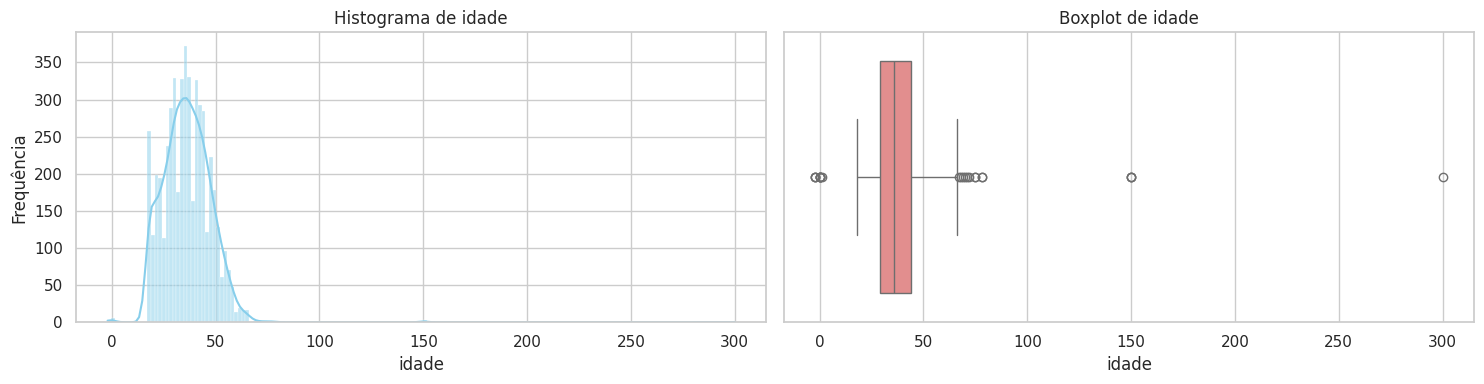

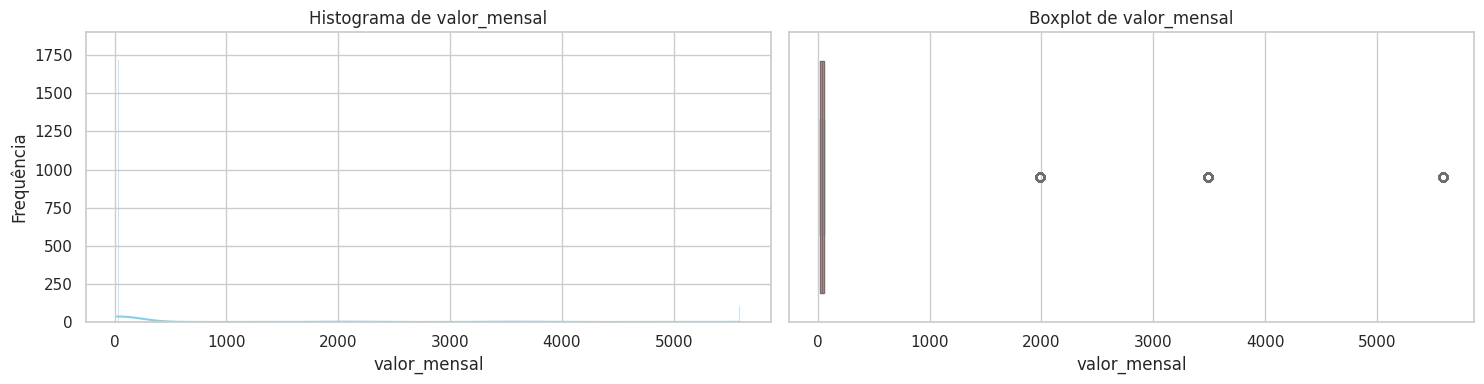

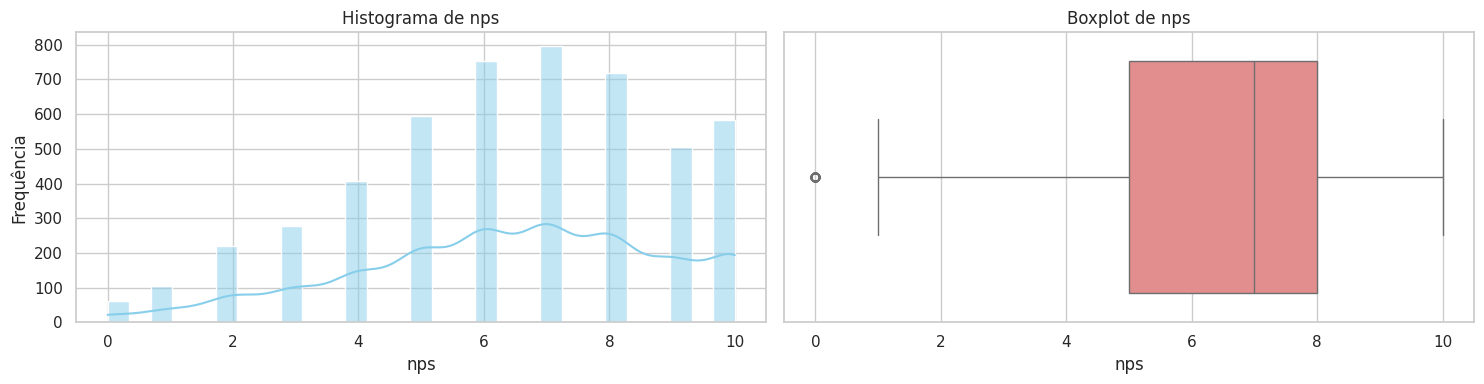

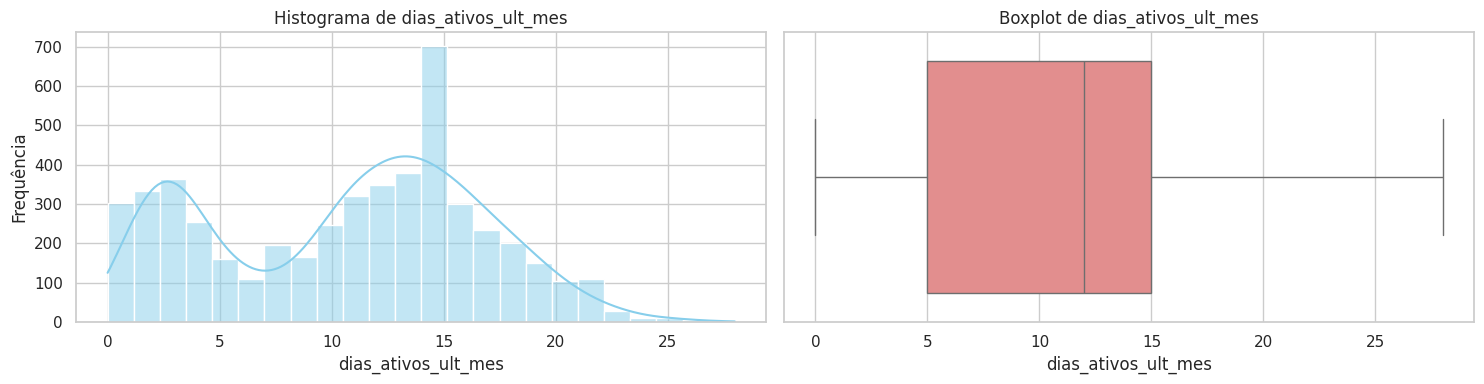

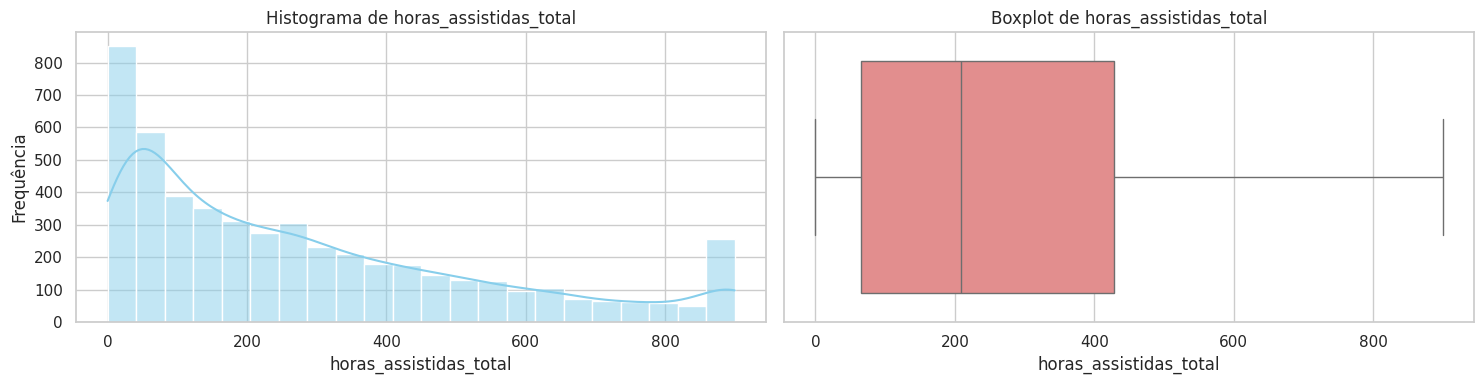

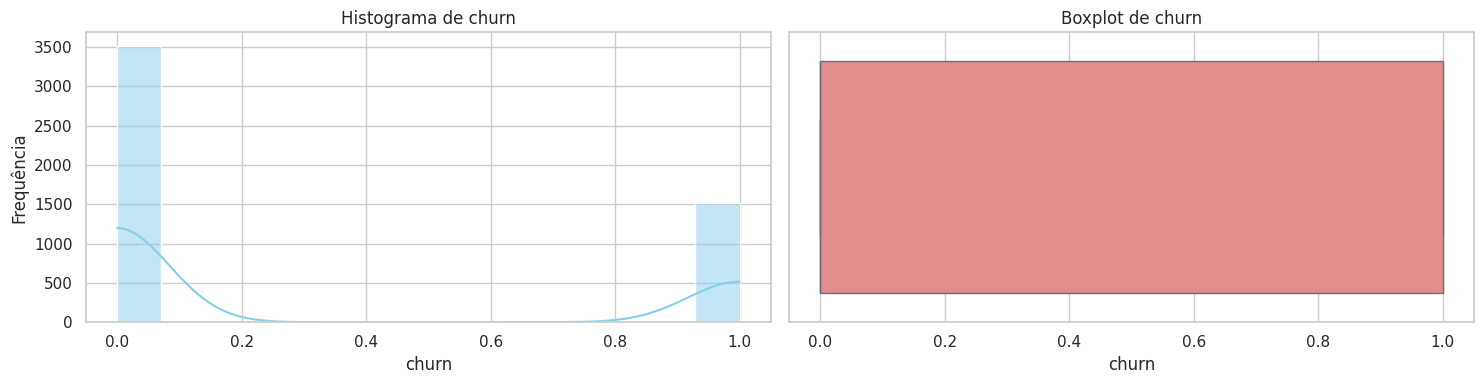

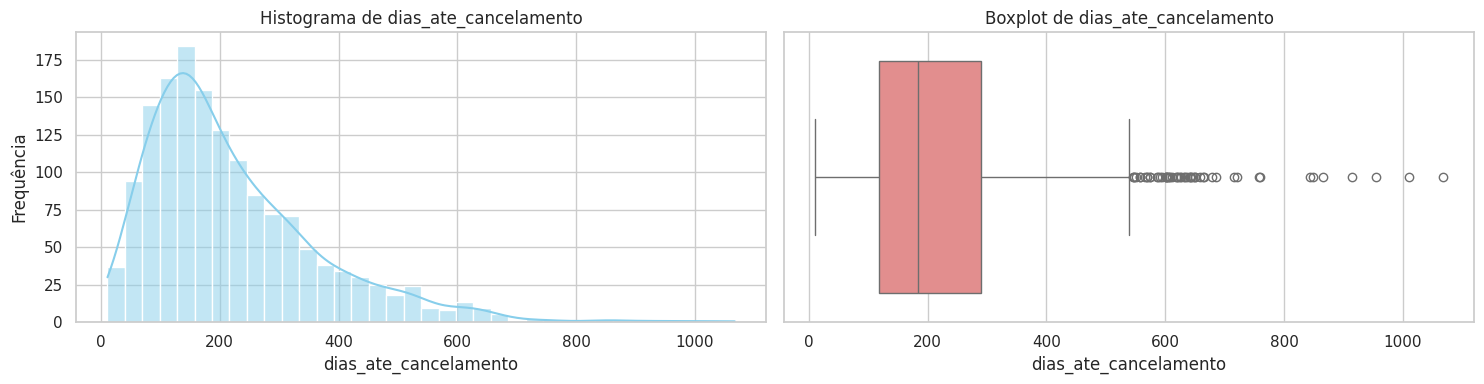

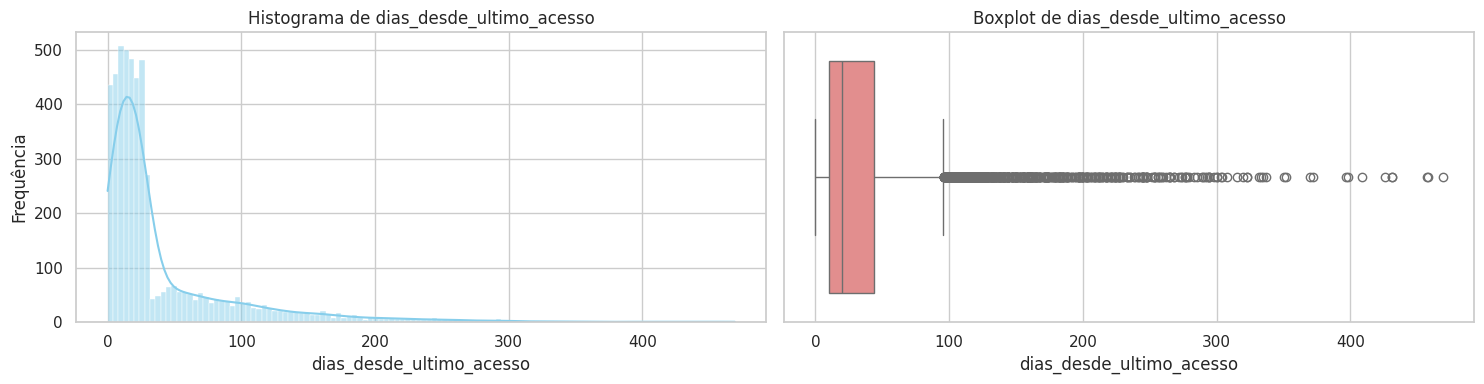

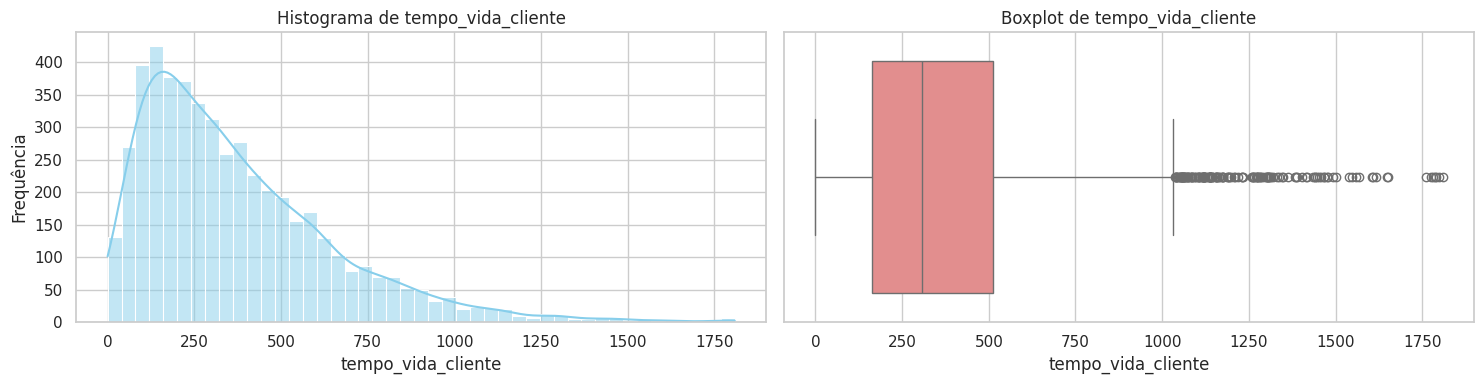

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de colunas numéricas excluindo 'cliente_id'
colunas_plot = [col for col in colunas_numericas if col != 'cliente_id']

sns.set_theme(style="whitegrid")

# Loop para gerar um Histograma e um Boxplot lado a lado para cada variável
for col in colunas_plot:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    # Histograma
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histograma de {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequência')

    # Boxplot
    sns.boxplot(x=df[col], ax=axes[1], color='lightcoral')
    axes[1].set_title(f'Boxplot de {col}')
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

In [97]:
# Criando o filtro para idades consistentes (entre 18 e 90 anos)
filtro_idade = (df['idade'] >= 18) & (df['idade'] <= 90)

# Exibindo o tamanho antes de filtrar
tamanho_anterior = len(df)

# Aplicando o filtro no DataFrame
df = df[filtro_idade].copy()

# Resultados
tamanho_atual = len(df)
print(f"Tamanho do DataFrame antes do filtro de idade: {tamanho_anterior}")
print(f"Tamanho do DataFrame após o filtro de idade: {tamanho_atual}")
print(f"Linhas com idades inconsistentes (fora do intervalo 18-90) removidas: {tamanho_anterior - tamanho_atual}")

Tamanho do DataFrame antes do filtro de idade: 5024
Tamanho do DataFrame após o filtro de idade: 5011
Linhas com idades inconsistentes (fora do intervalo 18-90) removidas: 13


In [98]:
# Filtra e exibe os registros onde o valor mensal é superior a 1000
valores_mensais_altos = df[df['valor_mensal'] > 1000]

print(f"Quantidade de registros com valor mensal maior que 1000: {len(valores_mensais_altos)}")
display(valores_mensais_altos)

Quantidade de registros com valor mensal maior que 1000: 602


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente
3,3454,46,Basico,Anual,1990.0,Sul,Google,10,2023-04-02,NaT,2024-01-13,2024-01-31,19,385.0,NaN,0,NaN,18.0,286.0
14,5581,18,Padrão,Mensal,3490.0,Sudeste,Organico,7,2023-07-22,NaT,2024-01-27,2024-01-31,15,160.7,NaN,0,NaN,4.0,189.0
29,5979,31,Padrão,Mensal,3490.0,Sudeste,Instagram,10,2023-08-22,NaT,2024-01-03,2024-01-31,14,117.2,NaN,0,NaN,28.0,134.0
34,1433,56,Padrão,Anual,3490.0,NaN,Organico,9,2023-04-14,NaT,2024-01-22,2024-01-31,11,180.4,NaN,0,NaN,9.0,283.0
42,4776,61,Basico,Anual,1990.0,Sudeste,Organico,4,2023-10-01,2023-12-15,2023-11-25,2024-01-31,6,47.8,problema tecnico,1,75.0,67.0,55.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4979,4984,30,Padrão,Anual,3490.0,Sudeste,Indicacao,7,2020-12-01,NaT,2024-01-13,2024-01-31,20,900.0,NaN,0,NaN,18.0,1138.0
4991,2396,23,Padrão,Anual,3490.0,Nordeste,Organico,8,2021-04-14,NaT,2024-01-26,2024-01-31,18,900.0,NaN,0,NaN,5.0,1017.0
5000,5926,37,Padrão,Anual,3490.0,Centro-Oeste,Organico,10,2022-12-01,NaT,2024-01-07,2024-01-31,9,243.6,NaN,0,NaN,24.0,402.0
5006,4388,18,Basico,Anual,1990.0,Nordeste,Instagram,9,2023-05-03,NaT,2024-01-09,2024-01-31,11,160.6,NaN,0,NaN,22.0,251.0


In [99]:
# Conta a frequência de cada valor distinto na coluna valor_mensal
print("--- Contagem de valores distintos em valor_mensal ---")
display(df['valor_mensal'].value_counts())

--- Contagem de valores distintos em valor_mensal ---


,count
valor_mensal,
19.9,1806
34.9,1712
55.9,891
1990.0,252
3490.0,246
5590.0,104


In [100]:
import numpy as np

# Divide por 100 todos os valores da coluna 'valor_mensal' que forem superiores a 1900
df.loc[df['valor_mensal'] > 1900, 'valor_mensal'] = df.loc[df['valor_mensal'] > 1900, 'valor_mensal'] / 100

# Exibe a nova contagem de valores distintos para conferência
print("--- Contagem de valores distintos em valor_mensal (corrigido) ---")
display(df['valor_mensal'].value_counts())


--- Contagem de valores distintos em valor_mensal (corrigido) ---


,count
valor_mensal,
19.9,2058
34.9,1958
55.9,995


In [101]:
# 1. Cálculo da recencia (diferença da data de último acesso para a data de extração)
df['recencia'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# 2. Cálculo dos meses_assinatura
# Se a data de cancelamento for nula, usamos (data_extracao - data_assinatura) / 30
# Caso contrário, usamos (data_cancelamento - data_assinatura) / 30
condicao_ativo = df['data_cancelamento'].isna()

df['meses_assinatura'] = np.where(
    condicao_ativo,
    (df['data_extracao'] - df['data_assinatura']).dt.days / 30.0,
    (df['data_cancelamento'] - df['data_assinatura']).dt.days / 30.0
)

# 3. Cálculo da receita_acumulada (valor_mensal multiplicado por meses_assinatura)
df['receita_acumulada'] = df['valor_mensal'] * df['meses_assinatura']

# Exibe as novas colunas para conferência
colunas_visualizar = ['data_assinatura', 'data_cancelamento', 'data_extracao', 'valor_mensal', 'recencia', 'meses_assinatura', 'receita_acumulada']
display(df[colunas_visualizar].head(10))


,data_assinatura,data_cancelamento,data_extracao,valor_mensal,recencia,meses_assinatura,receita_acumulada
0,2023-04-11,NaT,2024-01-31,19.9,2.0,9.833333,195.683333
1,2022-06-02,NaT,2024-01-31,34.9,1.0,20.266667,707.306667
2,2021-03-20,2022-11-17,2024-01-31,55.9,457.0,20.233333,1131.043333
3,2023-04-02,NaT,2024-01-31,19.9,18.0,10.133333,201.653333
4,2023-04-21,NaT,2024-01-31,19.9,15.0,9.500000,189.050000
5,2022-11-22,NaT,2024-01-31,55.9,11.0,14.500000,810.550000
6,2023-10-12,2023-12-28,2024-01-31,19.9,53.0,2.566667,51.076667
7,2022-01-21,NaT,2024-01-31,34.9,19.0,24.666667,860.866667
8,2023-04-26,2023-12-17,2024-01-31,19.9,55.0,7.833333,155.883333
9,2023-10-07,NaT,2024-01-31,19.9,6.0,3.866667,76.946667


## Conclusões da Analise Univariada - Variáveis categóricas

**1. Base suja**

- **Muitas nomenclaturas com nomes alternados que tinham o mesmo significado.
Podemos citar como exemplo para a coluna plano que continha "BASICO"/"básico"/"Basico" e o mesmo se repetia para as colunas de canal_aquisicao**

- **Foi encontrado o valor '?' em regiao e continha 170 registros com este valor e representa mais de 3% da base, tratá-lo como uma categoria valida criaria uma 'região ?' nos gráficos, a medida adotada foi tranforma-lo em nulo**

**2. Insight de negócio**

- **Alta concentração de clientes na região Sudeste que representa 42% dos clientes e Norte é  região com menos cliente (408) o que fará com que uma analise de churn nesta região tenha mais incertezas.**

- **75% dos clientes se encontram no plano Mensal**

- **Distribuição de canais é equilibrada.**

In [102]:
# Cria o novo DataFrame 'df_analise' com o filtro especificado
diferenca_dias = (df['data_extracao'] - df['data_assinatura']).dt.days
df_analise = df[diferenca_dias >= 220].copy()

# Exibe informações sobre o novo DataFrame
print(f"Tamanho do DataFrame original: {len(df)}")
print(f"Tamanho do DataFrame filtrado (df_analise): {len(df_analise)}")
display(df_analise.head())

Tamanho do DataFrame original: 5011
Tamanho do DataFrame filtrado (df_analise): 3668


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_ate_cancelamento,dias_desde_ultimo_acesso,tempo_vida_cliente,recencia,meses_assinatura,receita_acumulada
0,5746,36,Basico,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaT,...,15,276.0,NaN,0,NaN,2.0,293.0,2.0,9.833333,195.683333
1,4100,48,Padrão,Mensal,34.9,Sudeste,Organico,8,2022-06-02,NaT,...,14,394.9,NaN,0,NaN,1.0,607.0,1.0,20.266667,707.306667
2,4690,48,Premium,Mensal,55.9,Nordeste,Organico,4,2021-03-20,2022-11-17,...,5,257.0,PREÇO,1,607.0,457.0,590.0,457.0,20.233333,1131.043333
3,3454,46,Basico,Anual,19.9,Sul,Google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,18.0,286.0,18.0,10.133333,201.653333
4,1437,46,Basico,Mensal,19.9,Norte,Indicacao,8,2023-04-21,NaT,...,11,205.3,NaN,0,NaN,15.0,270.0,15.0,9.500000,189.050000



============================== ANÁLISE DA VARIÁVEL: idade ==============================


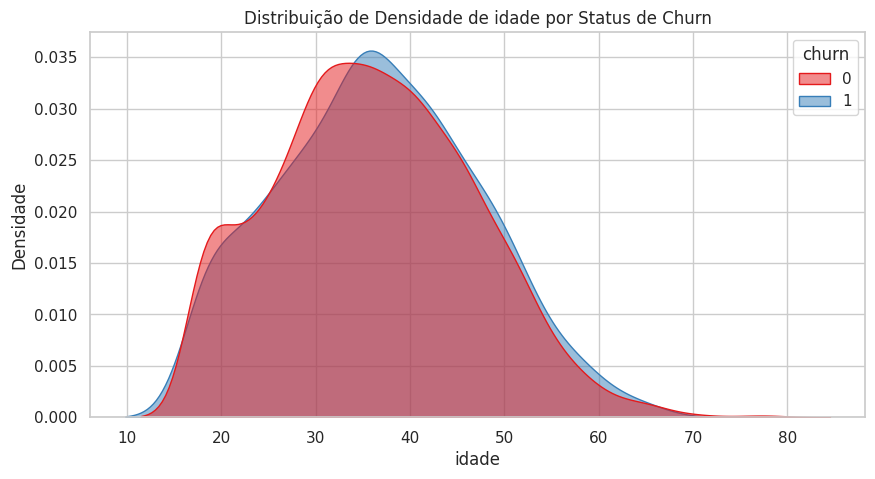

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,36.125540,10.633567,18.0,29.0,36.0,44.0,78.0
1,888.0,36.632883,10.600266,18.0,29.0,36.0,44.0,66.0



============================== ANÁLISE DA VARIÁVEL: valor_mensal ==============================


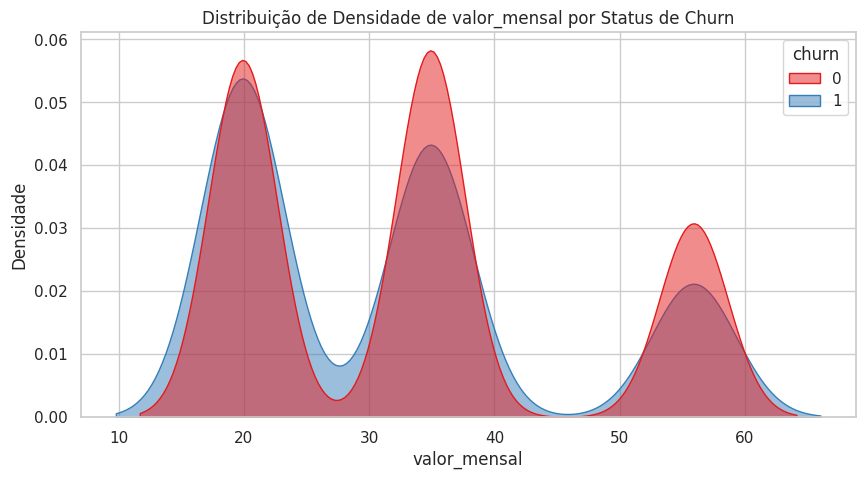

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,33.496043,13.370968,19.9,19.9,34.9,34.9,55.9
1,888.0,31.835811,13.119920,19.9,19.9,34.9,34.9,55.9



============================== ANÁLISE DA VARIÁVEL: nps ==============================


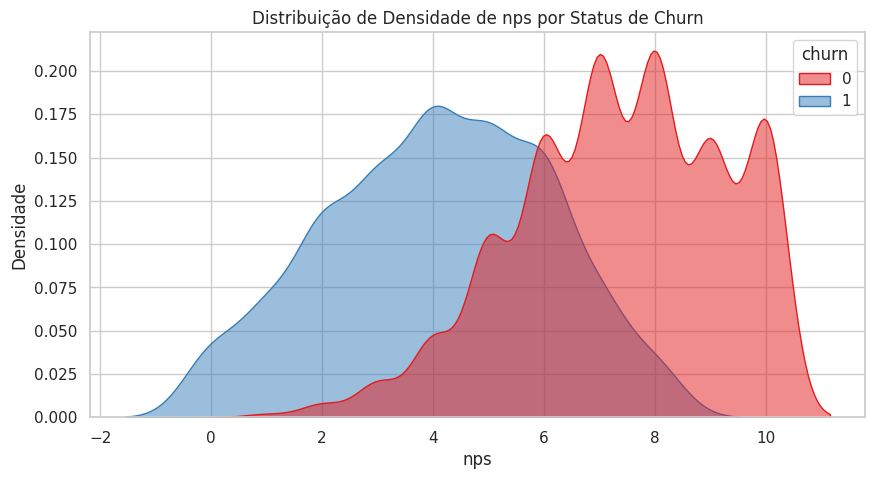

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,7.376978,1.877014,1.0,6.0,7.0,9.0,10.0
1,888.0,4.090090,2.004165,0.0,3.0,4.0,6.0,8.0



============================== ANÁLISE DA VARIÁVEL: dias_ativos_ult_mes ==============================


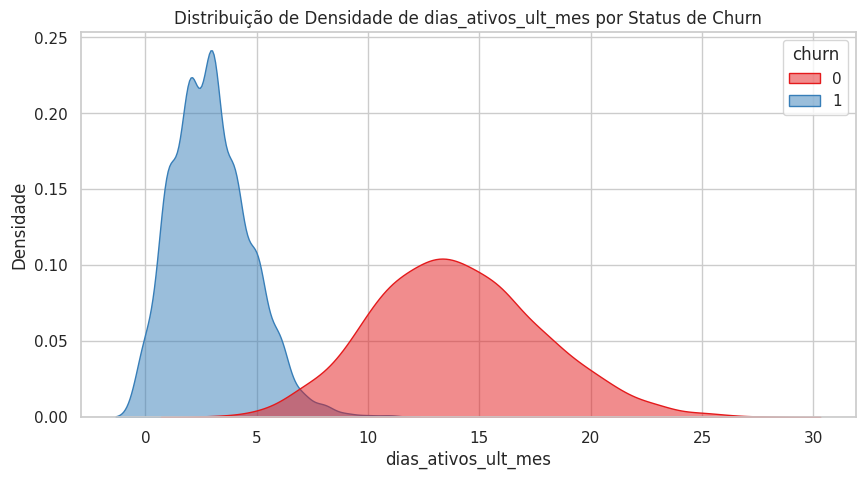

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,13.995324,3.755046,3.0,11.0,14.0,16.0,28.0
1,888.0,2.967342,1.721950,0.0,2.0,3.0,4.0,11.0



============================== ANÁLISE DA VARIÁVEL: horas_assistidas_total ==============================


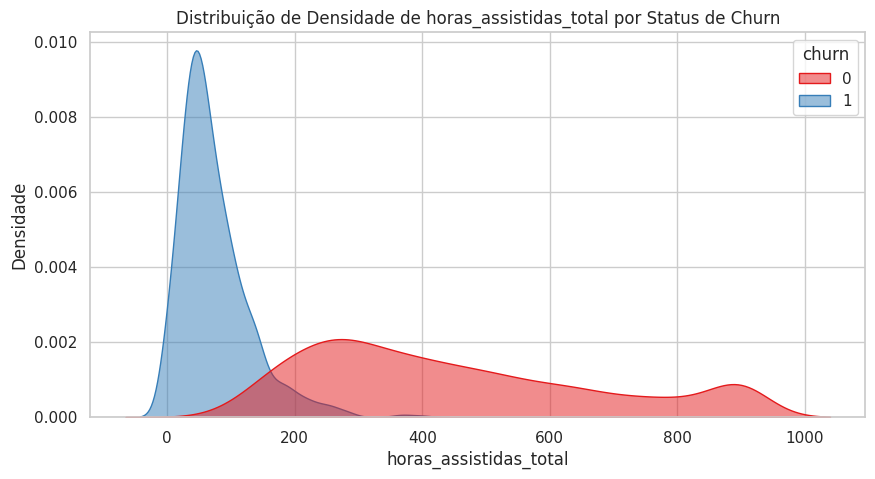

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,448.891475,226.739374,73.9,265.450,395.60,600.9,900.0
1,888.0,73.143131,55.191559,0.0,35.925,58.95,96.6,400.0



============================== ANÁLISE DA VARIÁVEL: tempo_vida_cliente ==============================


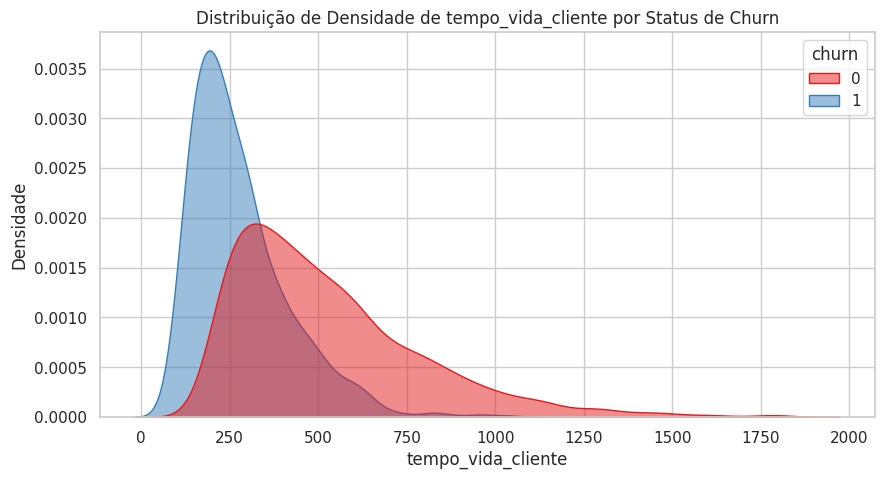

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2755.0,528.301270,266.179458,192.0,327.0,465.0,659.0,1809.0
1,878.0,278.715262,138.580418,90.0,176.0,244.0,342.5,1040.0



============================== ANÁLISE DA VARIÁVEL: diff_data_assinatura__data_extracao ==============================


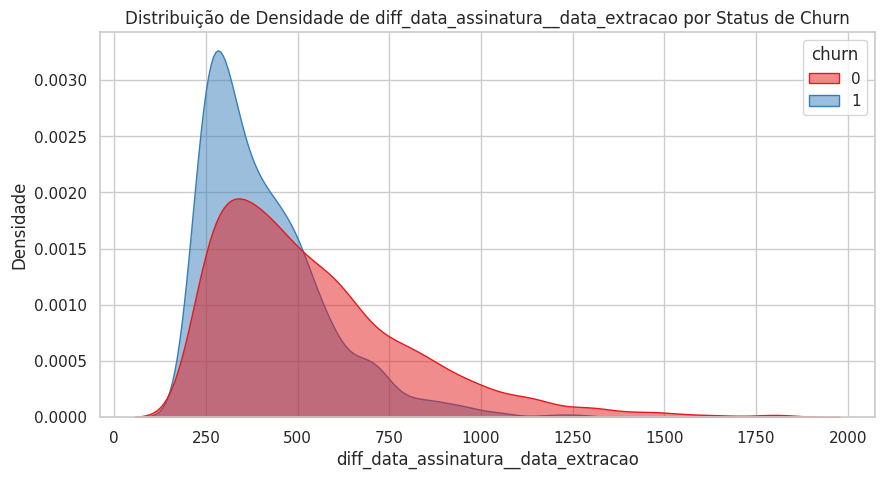

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,542.666187,265.461831,220.0,341.0,481.0,673.25,1815.0
1,888.0,409.548423,166.733604,220.0,282.0,364.5,495.00,1276.0



============================== ANÁLISE DA VARIÁVEL: recencia ==============================


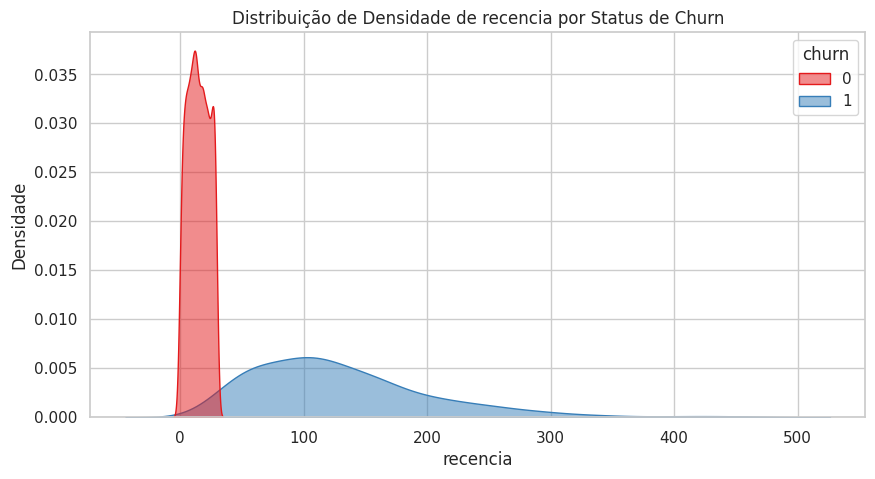

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2755.0,14.603993,8.493044,0.0,8.00,14.0,22.0,29.0
1,878.0,130.011390,74.106997,13.0,75.25,117.0,165.0,469.0



============================== ANÁLISE DA VARIÁVEL: meses_assinatura ==============================


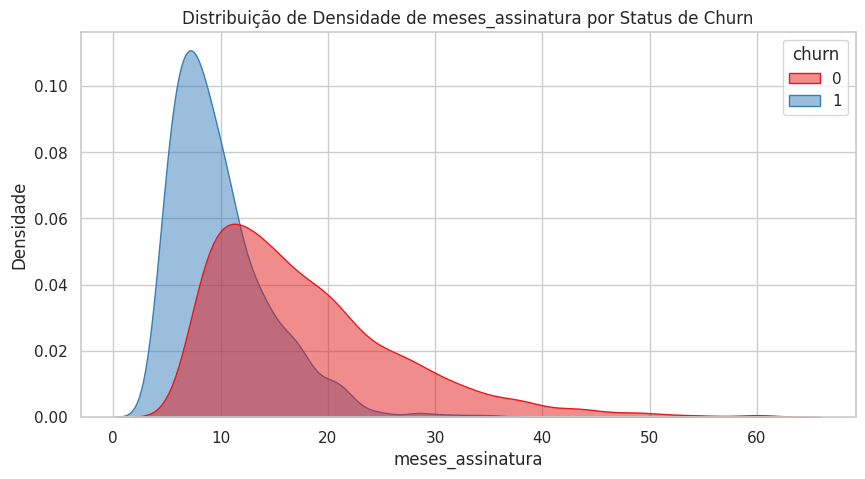

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,18.088873,8.848728,7.333333,11.366667,16.033333,22.441667,60.500000
1,888.0,10.006156,4.615595,3.800000,6.666667,8.900000,12.108333,35.566667



============================== ANÁLISE DA VARIÁVEL: receita_acumulada ==============================


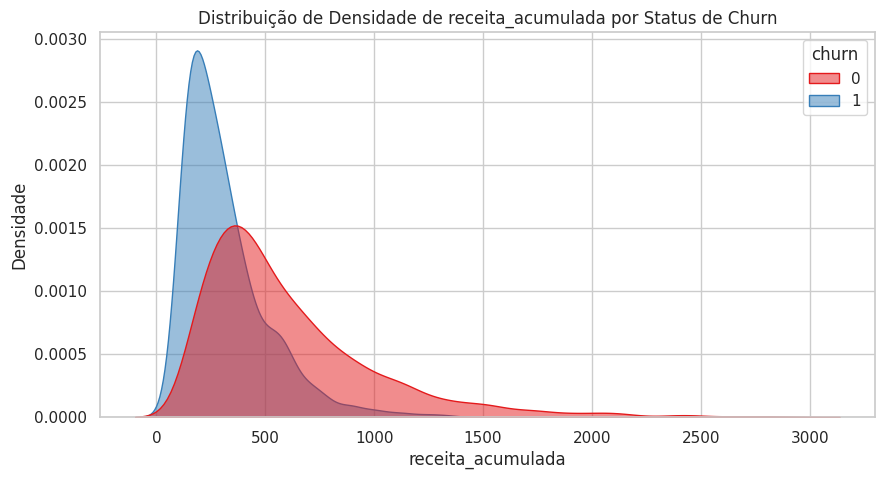

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,605.311556,396.917467,145.933333,329.013333,491.508333,762.103333,2893.756667
1,888.0,315.519917,195.137065,77.610000,172.173333,262.680000,392.043333,1341.600000


In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustando os nomes das variáveis com base nas colunas reais disponíveis no df_analise
# 'diff_data_assinatura__data_ultimo_acesso' corresponde a 'tempo_vida_cliente'
# 'diff_data_assinatura__data_extracao' será calculada como a diferença em dias entre assinatura e extração

df_analise['diff_data_assinatura__data_extracao'] = (df_analise['data_extracao'] - df_analise['data_assinatura']).dt.days

vars_numericas = [
    'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes',
    'horas_assistidas_total', 'tempo_vida_cliente',
    'diff_data_assinatura__data_extracao', 'recencia',
    'meses_assinatura', 'receita_acumulada'
]

sns.set_theme(style="whitegrid")

# Análise de Variáveis Numéricas
for col in vars_numericas:
    if col in df_analise.columns:
        print(f"\n{'='*30} ANÁLISE DA VARIÁVEL: {col} {'='*30}")

        # 1. Histograma de densidade sobreposto
        plt.figure(figsize=(10, 5))
        sns.kdeplot(data=df_analise, x=col, hue='churn', fill=True, common_norm=False, palette='Set1', alpha=0.5)
        plt.title(f'Distribuição de Densidade de {col} por Status de Churn')
        plt.xlabel(col)
        plt.ylabel('Densidade')
        plt.show()

        # 2. Tabela de estatísticas descritivas por grupo de Churn
        estatisticas = df_analise.groupby('churn')[col].describe()
        display(estatisticas)
    else:
        print(f"Coluna {col} não encontrada no DataFrame.")

In [104]:
# Análise de Variáveis Categóricas
vars_categoricas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

print(f"\n{'='*30} TAXA DE CHURN POR CATEGORIA {'='*30}")
for col in vars_categoricas:
    if col in df_analise.columns:
        # Calcula a taxa de churn em porcentagem
        tabela_churn = df_analise.groupby(col)['churn'].agg(
            Total_Clientes='count',
            Quantidade_Churn='sum',
            Taxa_Churn=lambda x: f"{(x.mean() * 100):.2f}%"
        ).reset_index()

        print(f"\nTaxa de Churn por: {col}")
        display(tabela_churn)
    else:
        print(f"Coluna {col} não encontrada no DataFrame.")


============================== TAXA DE CHURN POR CATEGORIA ==============================

Taxa de Churn por: plano


,plano,Total_Clientes,Quantidade_Churn,Taxa_Churn
0,Basico,1486,404,27.19%
1,Padrão,1436,325,22.63%
2,Premium,746,159,21.31%



Taxa de Churn por: ciclo


,ciclo,Total_Clientes,Quantidade_Churn,Taxa_Churn
0,Anual,916,220,24.02%
1,Mensal,2752,668,24.27%



Taxa de Churn por: regiao


,regiao,Total_Clientes,Quantidade_Churn,Taxa_Churn
0,Centro-Oeste,353,93,26.35%
1,Nordeste,719,172,23.92%
2,Norte,297,76,25.59%
3,Sudeste,1464,338,23.09%
4,Sul,707,174,24.61%



Taxa de Churn por: canal_aquisicao


,canal_aquisicao,Total_Clientes,Quantidade_Churn,Taxa_Churn
0,Google,635,172,27.09%
1,Indicacao,797,181,22.71%
2,Instagram,1125,280,24.89%
3,Organico,1111,255,22.95%


Conclusões análise bivariada
Aqui estão os insights só da bivariada, com os números do notebook (recorte maduro, ≥220 dias):

Premissa: análise feita sobre clientes com pelo menos 220 dias de assinatura — o recorte que garante que a pessoa teve tempo real de dar churn.

1. NPS é o sinal mais forte E é um sinal honesto: o NPS é declarado ao longo da relação, não é consequência mecânica do churn. É a primeira candidata a virar alerta precoce de cancelamento.

2. Idade e valor do plano praticamente não separam. Idade idêntica nos dois grupos (36 vs 36) e valor mensal consequencia do plano básico x premium. É um achado útil: descarta hipóteses óbvias e evita que o time gaste energia segmentando por essas variáveis.

3. Ciclo e região. Anual e mensal têm composição praticamente igual entre churners e não-churners, e a região, vemos maior diferença de churn no Norte e Centro-oeste. O caso do ciclo é contraintuitivo — o compromisso do plano anual não está segurando ninguém de forma perceptível. (Vale lembrar que 75% da base é mensal, o que reduz o contraste possível.)

4. Canal de aquisição tem efeito leve, mas com valor de negócio. Quem vem de indicação retém um pouco mais do que quem vem do google e outros canais. Conecta com decisão de marketing: a origem do cliente carrega alguma informação sobre a fidelidade dele — canais diferentes trazem clientes com propensões diferentes.

5. As variáveis de engajamento PARECEM separar espetacularmente — armadilha. Dias ativos (14 vs 3), horas assistidas (449 vs 73) e recência (15 vs 130 dias) mostram as maiores diferenças de toda a análise. Mas são contaminadas por vazamento de target: a pessoa parou de usar porque saiu, não o contrário *churn causa a variável, não o contrário). A separação é quase circular — elas descrevem o churn que já aconteceu, não o antecipam. Usá-las como "causa" seria o erro mais caro da análise.

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparação dos Dados
# Definir a coorte como o mês e ano da assinatura
df['cohort'] = df['data_assinatura'].dt.to_period('M')

# Definir o fim da permanência (data de cancelamento ou, se ativo, data de extração)
df['fim_permanencia'] = df['data_cancelamento'].fillna(df['data_extracao'])

# Calcular a diferença em meses entre a assinatura e o fim da permanência
def diff_meses(d1, d2):
    return (d1.dt.year - d2.dt.year) * 12 + (d1.dt.month - d2.dt.month)

df['meses_permanencia'] = diff_meses(df['fim_permanencia'], df['data_assinatura'])

# Garantir que permanência seja no mínimo 0
df['meses_permanencia'] = df['meses_permanencia'].clip(lower=0)

# 2. Expansão dos dados (um registro para cada mês em que o cliente esteve ativo)
linhas_expandidas = []
for idx, row in df.iterrows():
    for mes_vida in range(int(row['meses_permanencia']) + 1):
        linhas_expandidas.append({
            'cohort': row['cohort'],
            'cliente_id': row['cliente_id'],
            'mes_vida': mes_vida
        })

df_vida = pd.DataFrame(linhas_expandidas)

# 3. Montagem da Matriz de Cohort
# Agrupa por coorte e mês de vida para contar os clientes ativos
cohort_matrix = df_vida.groupby(['cohort', 'mes_vida'])['cliente_id'].nunique().unstack(fill_value=0)

# Calcula o tamanho original de cada coorte (mês de vida 0)
cohort_sizes = cohort_matrix[0]

# Converte os valores absolutos para porcentagem de retenção
cohort_retention = cohort_matrix.divide(cohort_sizes, axis=0)

# Criando rótulos amigáveis para o eixo Y incluindo o tamanho da coorte (n=...)
novos_rotulos_y = {cohort: f"{cohort} (n={cohort_sizes[cohort]})" for cohort in cohort_matrix.index}

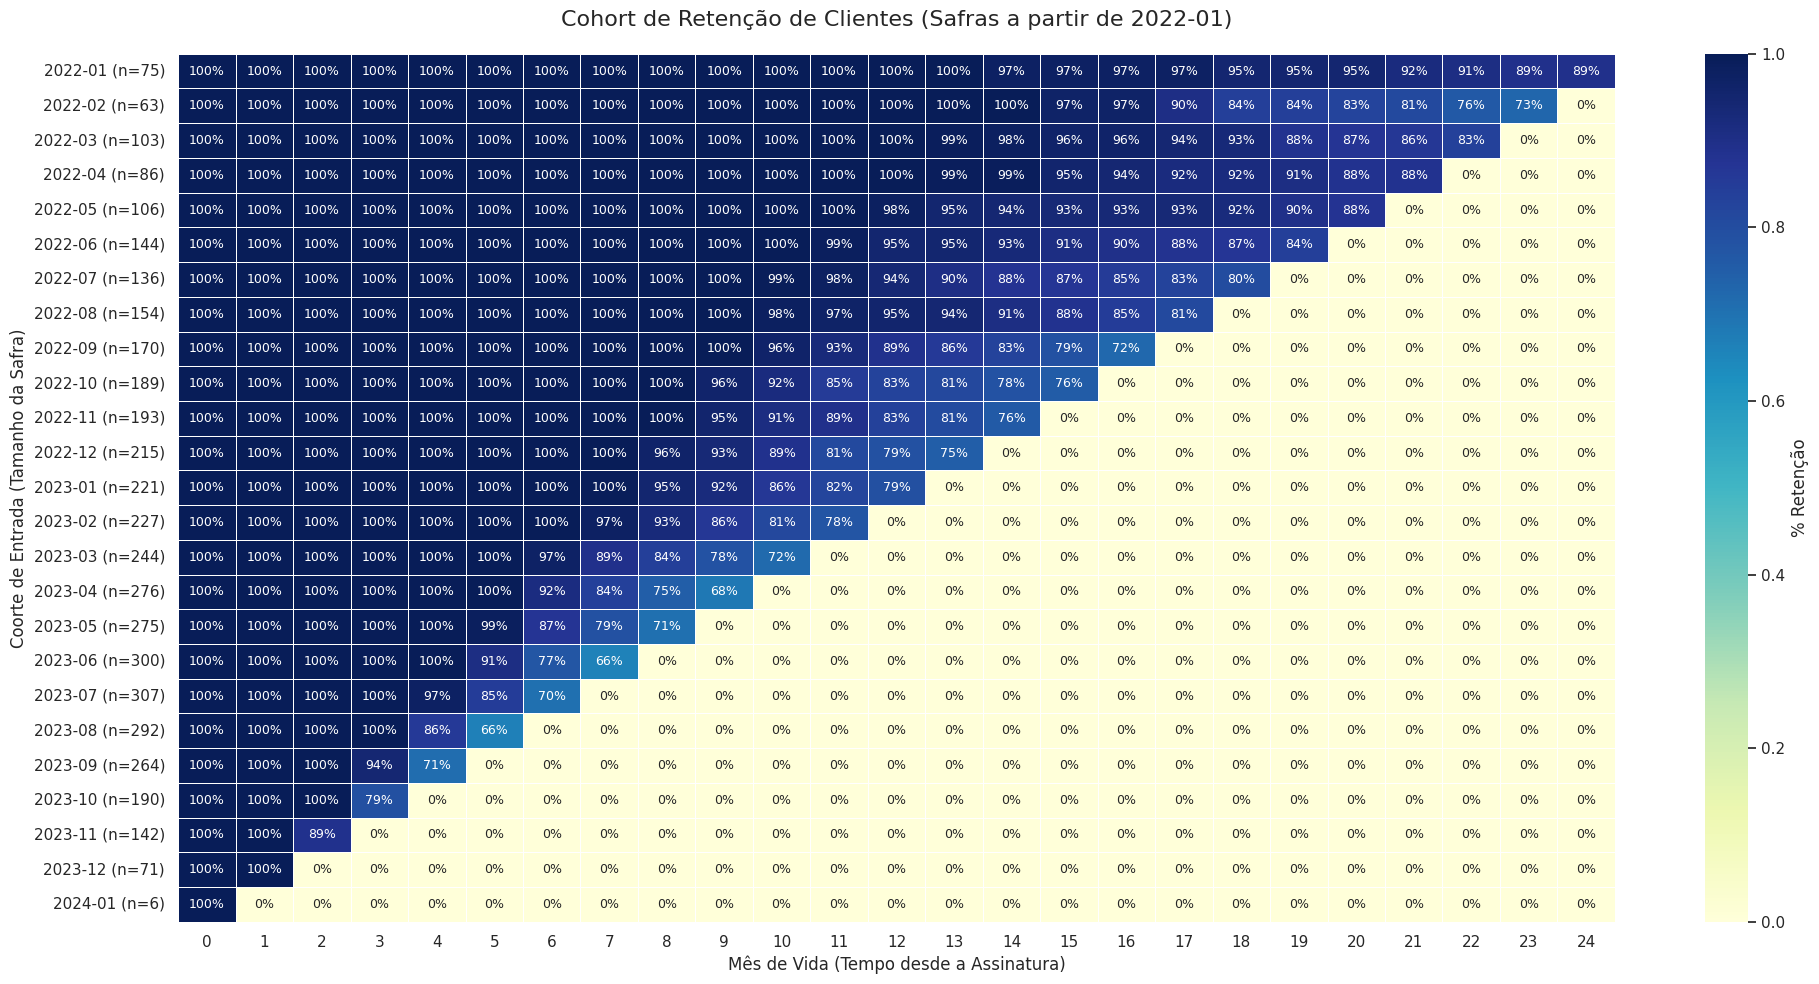

In [106]:
# 4. Visualização do Heatmap de Cohort

# Filtra as coortes a partir de dezembro de 2022
filtro_cohort = cohort_retention.index >= '2022-01'
retencao_filtrada = cohort_retention.loc[filtro_cohort]

# Seleciona apenas os primeiros 24 meses de vida (colunas de 0 a 24)
colunas_24 = [c for c in retencao_filtrada.columns if c <= 24]
retencao_filtrada = retencao_filtrada[colunas_24]

# Renomeia os índices para incluir o tamanho da cohort no eixo vertical
retencao_filtrada.index = retencao_filtrada.index.map(novos_rotulos_y)

# Configura o tamanho do gráfico para leitura confortável
plt.figure(figsize=(20, 10))

# Desenha o Heatmap
sns.heatmap(
    retencao_filtrada,
    annot=True,
    fmt=".0%",
    cmap="YlGnBu",
    annot_kws={"size": 9},
    linewidths=.5,
    cbar_kws={'label': '% Retenção'}
)

plt.title('Cohort de Retenção de Clientes (Safras a partir de 2022-01)', fontsize=16, pad=20)
plt.xlabel('Mês de Vida (Tempo desde a Assinatura)', fontsize=12)
plt.ylabel('Coorte de Entrada (Tamanho da Safra)', fontsize=12)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Há indício de que a retenção piorou nas safras recentes — as curvas de 2023 caem visivelmente mais rápido que as de 2022, que caem mais rápido que as de 2021. Isso é um sinal de negócio importante: a qualidade da aquisição ou a experiência do produto pode estar se deteriorando.

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Criando df_filtrado a partir do df limpo para garantir a consistência com o seu pedido
df_filtrado = df.copy()

# Passo 1: Filtrar apenas clientes ativos (churn == 0) e remover nulos na recência
df_rfm = df_filtrado[df_filtrado['churn'] == 0].copy()
df_rfm = df_rfm.dropna(subset=['recencia'])

# Passo 2: Atribuir notas de 1 a 5 usando quintis
# Para evitar erros de limites duplicados em variáveis com muitos empates,
# utilizamos o ranking com método 'first' para garantir quintis com distribuições iguais.

# Recência: menor valor é melhor -> nota 5 nos menores (invertemos os rótulos)
r_labels = [5, 4, 3, 2, 1]
df_rfm['R'] = pd.qcut(df_rfm['recencia'].rank(method='first'), q=5, labels=r_labels).astype(int)

# Frequência: maior valor é melhor
f_labels = [1, 2, 3, 4, 5]
df_rfm['F'] = pd.qcut(df_rfm['dias_ativos_ult_mes'].rank(method='first'), q=5, labels=f_labels).astype(int)

# Monetário: maior valor é melhor
m_labels = [1, 2, 3, 4, 5]
df_rfm['M'] = pd.qcut(df_rfm['valor_mensal'].rank(method='first'), q=5, labels=m_labels).astype(int)

# Exibindo os limites reais de cada pontuação (min e max em cada grupo) para transparência
print("=== LIMITES DOS GRUPOS ===")
for dim, col_orig in [('Recência (Dias)', 'recencia'), ('Frequência (Dias Ativos)', 'dias_ativos_ult_mes'), ('Monetário (Valor)', 'valor_mensal')]:
    print(f"\n{dim} por Nota:")
    grupo_limites = df_rfm.groupby(dim[0]).agg(
        Minimo=(col_orig, 'min'),
        Maximo=(col_orig, 'max'),
        Qtd_Clientes=(col_orig, 'count')
    )
    display(grupo_limites)

=== LIMITES DOS GRUPOS ===

Recência (Dias) por Nota:


,Minimo,Maximo,Qtd_Clientes
R,,,
1,23.0,29.0,693
2,17.0,23.0,693
3,11.0,17.0,693
4,6.0,11.0,693
5,0.0,6.0,693



Frequência (Dias Ativos) por Nota:


,Minimo,Maximo,Qtd_Clientes
F,,,
1,3,11,693
2,11,13,693
3,13,15,693
4,15,17,693
5,17,28,693



Monetário (Valor) por Nota:


,Minimo,Maximo,Qtd_Clientes
M,,,
1,19.9,19.9,693
2,19.9,34.9,693
3,34.9,34.9,693
4,34.9,55.9,693
5,55.9,55.9,693


In [115]:
# Passo 3: Criar código RFM concatenando as notas
df_rfm['RFM_Code'] = 'R' + df_rfm['R'].astype(str) + 'F' + df_rfm['F'].astype(str) + 'M' + df_rfm['M'].astype(str)

# Passo 4: Classificar cada cliente num segmento com base nas notas R e F
def classificar_segmento(row):
    r = row['R']
    f = row['F']
    if r >= 4 and f >= 4:
        return "Engajados"
    elif r <= 2 and f >= 3:
        return "Em risco"
    elif r >= 4 and f <= 2:
        return "Novos/Ativos recentes"
    elif r <= 2 and f <= 2:
        return "Adormecidos"
    else:
        return "Regulares"

df_rfm['Segmento'] = df_rfm.apply(classificar_segmento, axis=1)

# Passo 5: Contagem e porcentagem de cada segmento
distribuicao = df_rfm['Segmento'].value_counts().reset_index()
distribuicao.columns = ['Segmento', 'Contagem']
distribuicao['Porcentagem'] = (distribuicao['Contagem'] / distribuicao['Contagem'].sum() * 100).round(2).astype(str) + '%'

print("\n=== DISTRIBUIÇÃO DOS SEGMENTOS ===")
display(distribuicao)


=== DISTRIBUIÇÃO DOS SEGMENTOS ===


,Segmento,Contagem,Porcentagem
0,Regulares,967,27.91%
1,Em risco,826,23.84%
2,Engajados,566,16.33%
3,Adormecidos,560,16.16%
4,Novos/Ativos recentes,546,15.76%


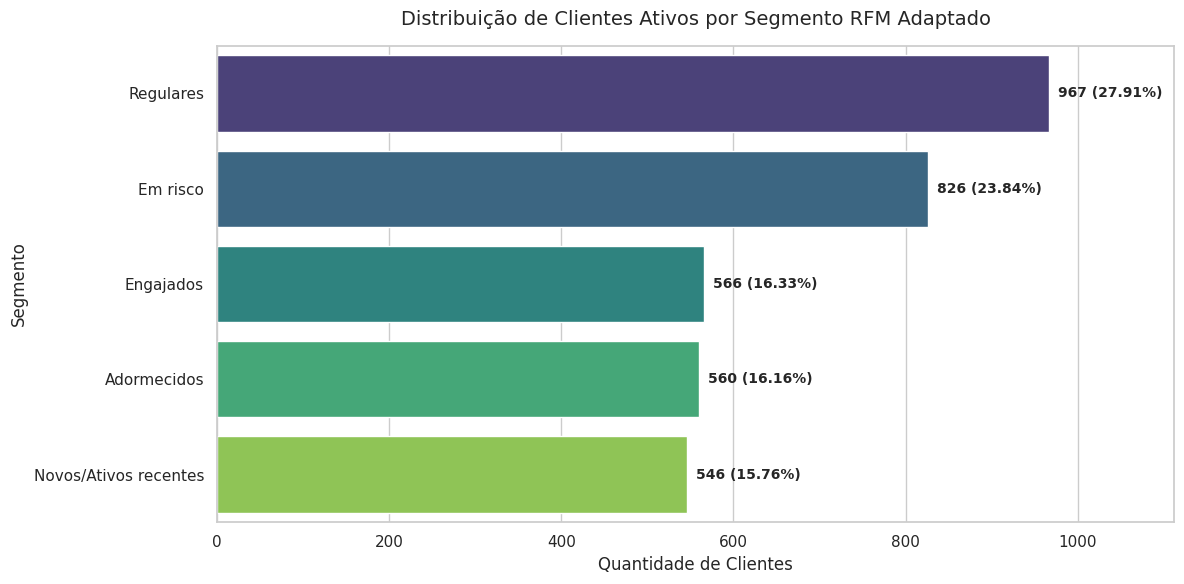

In [116]:
# Plotar gráfico de barras horizontais com a distribuição
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Contagem',
    y='Segmento',
    data=distribuicao,
    palette='viridis',
    hue='Segmento',
    legend=False
)

# Adicionar os rótulos numéricos com porcentagem no final de cada barra
for index, row in distribuicao.iterrows():
    plt.text(
        row['Contagem'] + 10,
        index,
        f"{row['Contagem']} ({row['Porcentagem']})",
        va='center',
        fontsize=10,
        fontweight='bold'
    )

plt.title('Distribuição de Clientes Ativos por Segmento RFM Adaptado', fontsize=14, pad=15)
plt.xlabel('Quantidade de Clientes')
plt.ylabel('Segmento')
plt.xlim(0, distribuicao['Contagem'].max() * 1.15)
plt.tight_layout()
plt.show()

In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

# Função para normalizar os textos (remover acentos, minúsculas e espaços extras)
def normalizar_texto(texto):
    if pd.isna(texto):
        return np.nan
    # Converte para minúsculas e remove espaços das bordas
    texto = str(texto).lower().strip()
    # Remove acentos
    texto = ''.join(
        c for c in unicodedata.normalize('NFD', texto)
        if unicodedata.category(c) != 'Mn'
    )
    return texto

# 1. Aplicando a normalização na coluna motivo_cancelamento
df_filtrado['motivo_cancelamento_limpo'] = df_filtrado['motivo_cancelamento'].apply(normalizar_texto)

# Filtrar apenas os cancelados (onde motivo_cancelamento_limpo não é nulo)
cancelamentos = df_filtrado[df_filtrado['motivo_cancelamento_limpo'].notna()].copy()

# 2. Contar frequência de cada motivo
pareto_data = cancelamentos['motivo_cancelamento_limpo'].value_counts().reset_index()
pareto_data.columns = ['Motivo', 'Quantidade']

# Calcular porcentagem e porcentagem acumulada
total_cancelamentos = pareto_data['Quantidade'].sum()
pareto_data['Porcentagem'] = (pareto_data['Quantidade'] / total_cancelamentos) * 100
pareto_data['Porcentagem_Acumulada'] = pareto_data['Porcentagem'].cumsum()

# Exibir a Tabela de Pareto formatada
pareto_exibicao = pareto_data.copy()
pareto_exibicao['Porcentagem'] = pareto_exibicao['Porcentagem'].round(2).astype(str) + '%'
pareto_exibicao['Porcentagem_Acumulada'] = pareto_exibicao['Porcentagem_Acumulada'].round(2).astype(str) + '%'

print("=== TABELA DE PARETO DOS MOTIVOS DE CANCELAMENTO ===")
display(pareto_exibicao)

# Identificar motivos que concentram ~80% dos cancelamentos
motivos_80 = pareto_data[pareto_data['Porcentagem_Acumulada'] <= 85]['Motivo'].tolist()
print(f"\nOs principais motivos que concentram cerca de 80% do churn são: {', '.join(motivos_80).upper()}")

=== TABELA DE PARETO DOS MOTIVOS DE CANCELAMENTO ===


,Motivo,Quantidade,Porcentagem,Porcentagem_Acumulada
0,preco,507,33.55%,33.55%
1,pouco conteudo novo,384,25.41%,58.97%
2,problema tecnico,249,16.48%,75.45%
3,falta de tempo,174,11.52%,86.96%
4,concorrente,130,8.6%,95.57%
5,outro,67,4.43%,100.0%



Os principais motivos que concentram cerca de 80% do churn são: PRECO, POUCO CONTEUDO NOVO, PROBLEMA TECNICO


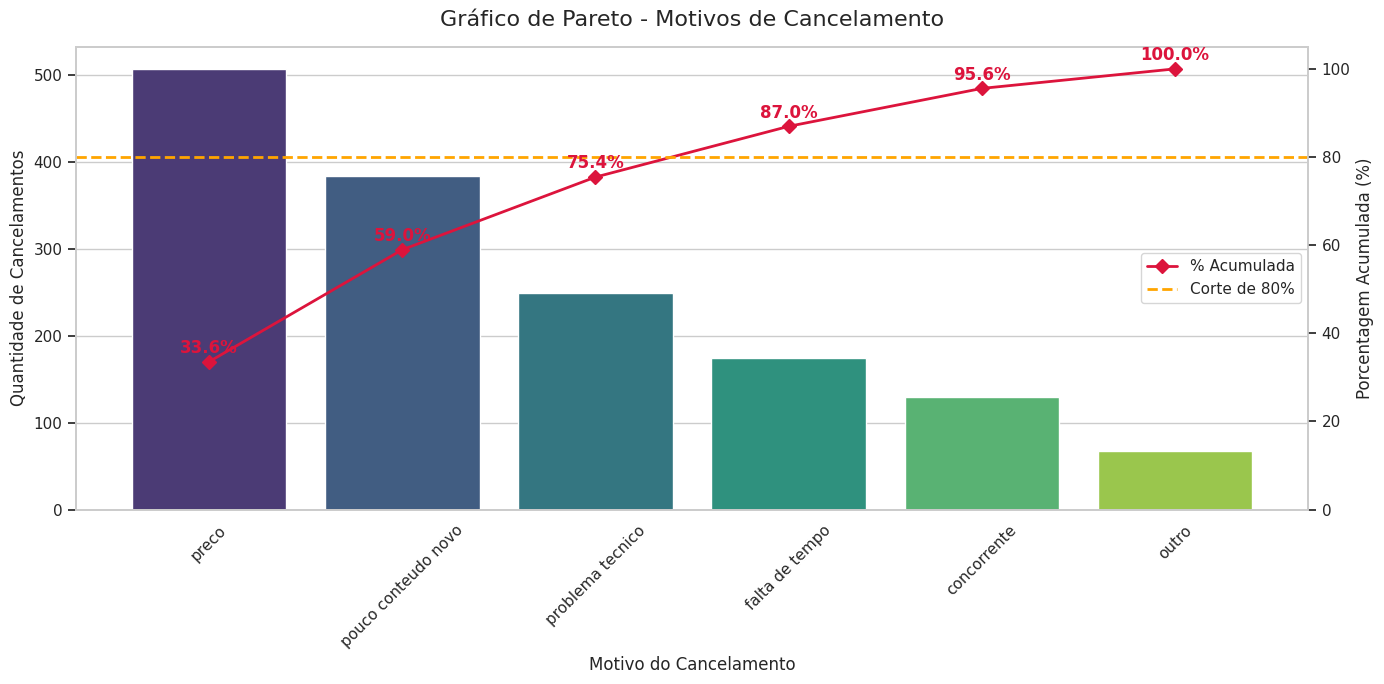

In [120]:
# 3. Plotagem do Gráfico de Pareto
fig, ax1 = plt.subplots(figsize=(14, 7))

# Gráfico de barras para quantidades (eixo Y esquerdo)
sns.barplot(
    x='Motivo',
    y='Quantidade',
    data=pareto_data,
    ax=ax1,
    palette='viridis',
    hue='Motivo',
    legend=False
)
ax1.set_title('Gráfico de Pareto - Motivos de Cancelamento', fontsize=16, pad=15)
ax1.set_xlabel('Motivo do Cancelamento', fontsize=12)
ax1.set_ylabel('Quantidade de Cancelamentos', fontsize=12)
ax1.tick_params(axis='x', rotation=45)

# Criando o segundo eixo Y à direita para a linha de porcentagem acumulada
ax2 = ax1.twinx()
ax2.plot(
    pareto_data['Motivo'],
    pareto_data['Porcentagem_Acumulada'],
    color='crimson',
    marker='D',
    ms=7,
    linewidth=2,
    label='% Acumulada'
)
ax2.set_ylabel('Porcentagem Acumulada (%)', fontsize=12)
ax2.set_ylim(0, 105)
ax2.grid(False)  # Evita sobreposição de grades de ambos os eixos

# Linha de referência horizontal de 80%
ax2.axhline(80, color='orange', linestyle='--', linewidth=2, label='Corte de 80%')

# Adiciona rótulos de texto com o valor acumulado em cada ponto da linha
for idx, row in pareto_data.iterrows():
    ax2.text(
        idx,
        row['Porcentagem_Acumulada'] + 2,
        f"{row['Porcentagem_Acumulada']:.1f}%",
        color='crimson',
        fontweight='bold',
        ha='center'
    )

# Legenda combinando a linha e o corte de 80%
lines, labels = ax2.get_legend_handles_labels()
ax2.legend(lines, labels, loc='center right')

plt.tight_layout()
plt.show()

*Principais Insights e Direcionamento de Negócio
Os 80% do Churn (Problemas Vitais):*

Apenas 3 motivos explicam aproximadamente 75,45% (quase os 80% teóricos) de todos os cancelamentos da base:

- Preço (33,55%)

- Pouco conteúdo novo (25,41%)

- Problema técnico (16,48%)


Plano de Ação Sugerido:

- Financeiro/Precificação: Sendo o preço o maior vilão (33,55%), vale a pena estudar campanhas de migração de planos mensais para planos anuais com descontos agressivos, ou ofertas de downgrade temporário em vez do cancelamento total.

- Engajamento e Conteúdo: 1 em cada 4 clientes cancela alegando falta de novidades no catálogo. Melhorar as recomendações e acelerar o ritmo de lançamentos pode mitigar essa perda.

- Estabilidade da Plataforma: Problemas técnicos são responsáveis por 16,48% das saídas. Este é um churn extremamente doloroso porque é inteiramente controlável. O time de engenharia e suporte de produto deve priorizar a resolução de bugs críticos de reprodução e usabilidade.

### Análise de Funil de Conversão (Onboarding)
Carregamento e limpeza inicial da base de eventos.

In [123]:
import pandas as pd

# Definindo o caminho correto fornecido pelo usuário
caminho_funil = '/content/drive/MyDrive/Estudos/Churn/funil_eventos.csv'

try:
    # Carrega o arquivo
    df_funil = pd.read_csv(caminho_funil)
    print(f"Quantidade de linhas antes de remover duplicadas: {len(df_funil)}")

    # Remove as linhas duplicadas
    df_funil = df_funil.drop_duplicates()
    print(f"Quantidade de linhas após remover duplicadas: {len(df_funil)}")

    # Exibe as primeiras linhas do DataFrame limpo
    display(df_funil.head())

    # Exibe informações gerais das colunas para entendermos a estrutura
    print("\n--- Estrutura do DataFrame ---")
    df_funil.info()

except FileNotFoundError:
    print(f"Erro: Arquivo não encontrado no caminho indicado: {caminho_funil}")
    print("Por favor, certifique-se de que o nome da pasta e do arquivo estão exatamente iguais no seu Drive.")

Quantidade de linhas antes de remover duplicadas: 12886
Quantidade de linhas após remover duplicadas: 12836


,cliente_id,etapa
0,2165,assistiu_1a_aula
1,3269,criou_conta
2,4589,criou_conta
3,5228,visitou_site
4,4620,assistiu_1a_aula



--- Estrutura do DataFrame ---
<class 'pandas.core.frame.DataFrame'>
Index: 12836 entries, 0 to 12885
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   cliente_id  12836 non-null  int64 
 1   etapa       12836 non-null  object
dtypes: int64(1), object(1)
memory usage: 300.8+ KB


In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Padronizar a escrita da coluna 'etapa'
df_funil['etapa'] = df_funil['etapa'].astype(str).str.lower().str.strip().str.replace(' ', '_')

# Ordem lógica do funil definida pelo usuário
ordem_funil = ['visitou_site', 'criou_conta', 'assistiu_1a_aula', 'assinou_plano', 'renovou']

# 2. Contar clientes únicos em cada etapa
contagem_etapas = []
for etapa in ordem_funil:
    clientes_unicos = df_funil[df_funil['etapa'] == etapa]['cliente_id'].nunique()
    contagem_etapas.append(clientes_unicos)

# Criar DataFrame base do funil
df_funil_analise = pd.DataFrame({
    'Etapa': ordem_funil,
    'Clientes_Unicos': contagem_etapas
})

# 3. Calcular taxas de conversão
# Conversão em relação ao topo (visitou_site)
topo_funil = df_funil_analise.loc[0, 'Clientes_Unicos']
df_funil_analise['Conversao_Topo_Percentual'] = (df_funil_analise['Clientes_Unicos'] / topo_funil) * 100

# Conversão em relação à etapa anterior
conversao_anterior = [100.0]  # O topo do funil é sempre 100%
for i in range(1, len(df_funil_analise)):
    anterior = df_funil_analise.loc[i-1, 'Clientes_Unicos']
    atual = df_funil_analise.loc[i, 'Clientes_Unicos']
    taxa = (atual / anterior) * 100 if anterior > 0 else 0
    conversao_anterior.append(taxa)

df_funil_analise['Conversao_Anterior_Percentual'] = conversao_anterior

# 4. Identificar o maior gargalo (etapa com a menor taxa de conversão em relação à anterior, excluindo o topo)
# Encontramos o menor valor a partir do índice 1
indice_gargalo = df_funil_analise.loc[1:, 'Conversao_Anterior_Percentual'].idxmin()
etapa_gargalo = df_funil_analise.loc[indice_gargalo, 'Etapa']
perda_gargalo = 100 - df_funil_analise.loc[indice_gargalo, 'Conversao_Anterior_Percentual']

# Exibir tabela formatada
tabela_exibicao = df_funil_analise.copy()
tabela_exibicao['Conversao_Anterior_Percentual'] = tabela_exibicao['Conversao_Anterior_Percentual'].round(2).astype(str) + '%'
tabela_exibicao['Conversao_Topo_Percentual'] = tabela_exibicao['Conversao_Topo_Percentual'].round(2).astype(str) + '%'

print("=== TABELA DE CONVERSÃO DO FUNIL DE ONBOARDING ===")
display(tabela_exibicao)

print(f"\n🚨 MAIOR GARGALO DETECTADO: A etapa '{etapa_gargalo.upper()}' possui a menor conversão em relação à anterior.")
print(f"Apenas {df_funil_analise.loc[indice_gargalo, 'Conversao_Anterior_Percentual']:.2f}% dos usuários avançaram para esta etapa (uma perda de {perda_gargalo:.2f}%).")

=== TABELA DE CONVERSÃO DO FUNIL DE ONBOARDING ===


,Etapa,Clientes_Unicos,Conversao_Topo_Percentual,Conversao_Anterior_Percentual
0,visitou_site,5000,100.0%,100.0%
1,criou_conta,3377,67.54%,67.54%
2,assistiu_1a_aula,2698,53.96%,79.89%
3,assinou_plano,1066,21.32%,39.51%
4,renovou,695,13.9%,65.2%



🚨 MAIOR GARGALO DETECTADO: A etapa 'ASSINOU_PLANO' possui a menor conversão em relação à anterior.
Apenas 39.51% dos usuários avançaram para esta etapa (uma perda de 60.49%).


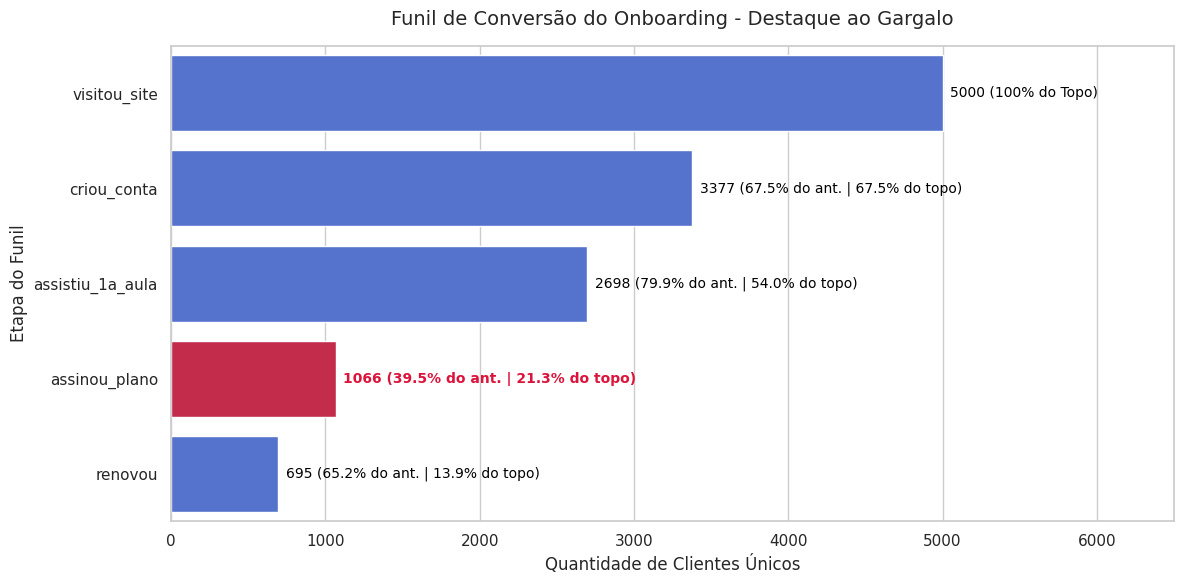

In [128]:
# 5. Plotar o funil de conversão com destaque ao gargalo
plt.figure(figsize=(12, 6))

# Criando paleta dinâmica: azul para as etapas normais e crimson para o gargalo
cores = ['royalblue' if etapa != etapa_gargalo else 'crimson' for etapa in df_funil_analise['Etapa']]

sns.barplot(
    x='Clientes_Unicos',
    y='Etapa',
    data=df_funil_analise,
    palette=cores,
    hue='Etapa',
    legend=False
)

# Adicionando os rótulos de dados com valores absolutos e conversões
for index, row in df_funil_analise.iterrows():
    qtd = int(row['Clientes_Unicos'])
    conv_topo = row['Conversao_Topo_Percentual']
    conv_ant = row['Conversao_Anterior_Percentual']

    if index == 0:
        texto = f"{qtd} (100% do Topo)"
    else:
        texto = f"{qtd} ({conv_ant:.1f}% do ant. | {conv_topo:.1f}% do topo)"

    plt.text(
        qtd + (df_funil_analise['Clientes_Unicos'].max() * 0.01),
        index,
        texto,
        va='center',
        fontsize=10,
        fontweight='bold' if row['Etapa'] == etapa_gargalo else 'normal',
        color='black' if row['Etapa'] != etapa_gargalo else 'crimson'
    )

plt.title('Funil de Conversão do Onboarding - Destaque ao Gargalo', fontsize=14, pad=15)
plt.xlabel('Quantidade de Clientes Únicos')
plt.ylabel('Etapa do Funil')
plt.xlim(0, df_funil_analise['Clientes_Unicos'].max() * 1.3) # Margem para os textos não cortarem
plt.tight_layout()
plt.show()